In [63]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [65]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volumen_binance,trades_binance,var_diaria_binance,rango_dia_binance,volatilidad_50_binance,...,momentum_200_dxy,SMA_50_dxy,EMA_50_dxy,SMA_200_dxy,EMA_200_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-01-01,16541.77,16628.00,16499.01,16616.75,96925.41374,3218355.0,0.449451,128.99,367.529453,...,-1.084069,105.275233,105.547776,107.887225,106.544019,41.998608,NaN,0,NaN,0
1,2023-01-02,16617.17,16799.23,16548.70,16672.87,121888.57191,4036118.0,0.337732,250.53,362.064797,...,0.617581,105.229899,105.497667,107.890425,106.521392,45.834443,NaN,0,NaN,0
2,2023-01-03,16672.78,16778.40,16605.28,16675.18,159541.53733,5097596.0,0.013855,173.12,361.616039,...,-0.171920,105.187099,105.459327,107.889525,106.501478,49.435670,NaN,0,NaN,0
3,2023-01-04,16675.65,16991.87,16652.66,16850.36,220362.18862,6310703.0,1.050543,339.21,361.374263,...,-0.367944,105.144099,105.411903,107.887600,106.479075,45.887346,NaN,0,NaN,0
4,2023-01-05,16850.36,16879.82,16753.00,16831.85,163473.56641,4842014.0,-0.109849,126.82,360.953339,...,0.449461,105.119299,105.397318,107.889950,106.464756,55.868588,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,2025-03-07,89931.88,91283.02,84667.03,86801.75,57980.35713,9510442.0,-3.480567,6615.99,6079.215982,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
797,2025-03-08,86801.74,86897.25,85218.47,86222.45,12989.23054,2553974.0,-0.667383,1678.78,6168.585303,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
798,2025-03-09,86222.46,86500.00,80000.00,80734.37,26115.39345,5189138.0,-6.365024,6500.00,6445.301805,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
799,2025-03-10,80734.48,84123.46,79332.00,80104.40,24622.30310,4965411.0,-0.780300,4791.46,6777.296313,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0


# Visualización de la variable respuesta (7 días)

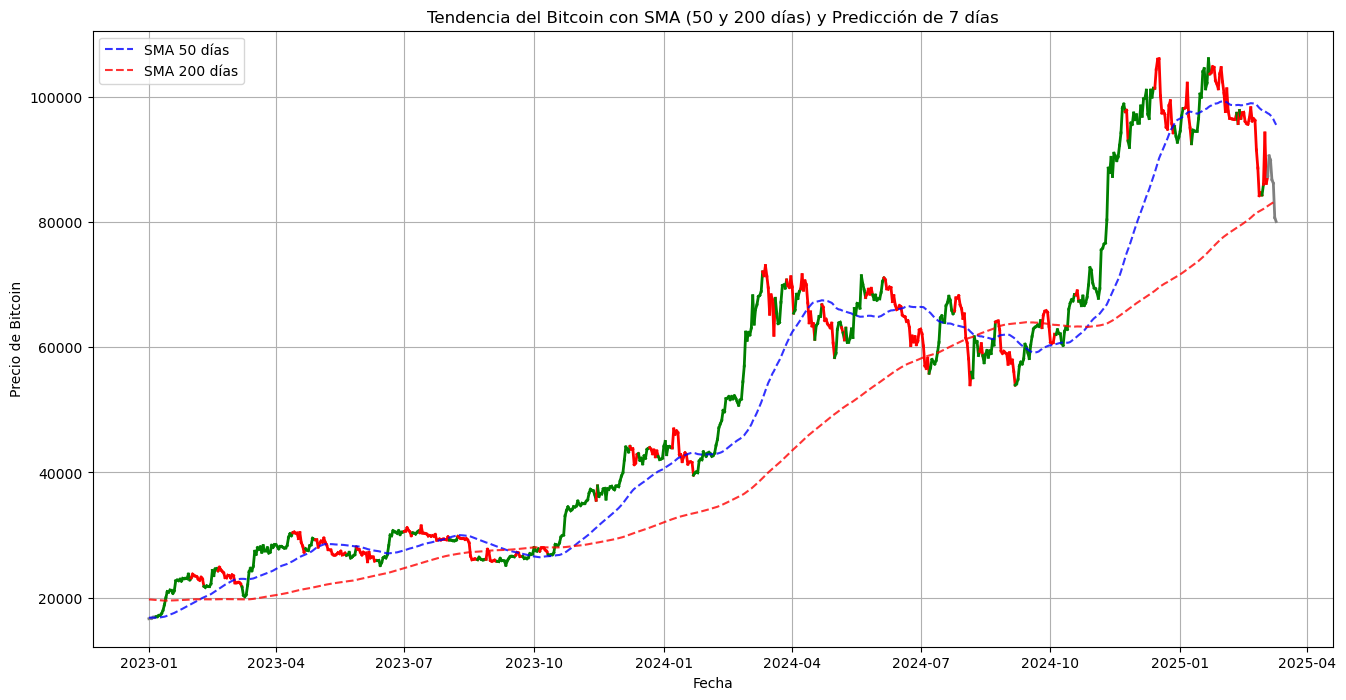

In [67]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_50_binance'], label="SMA 50 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_200_binance'], label="SMA 200 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (50 y 200 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Visualización de la volatilidad de la variable respuesta a 7 días

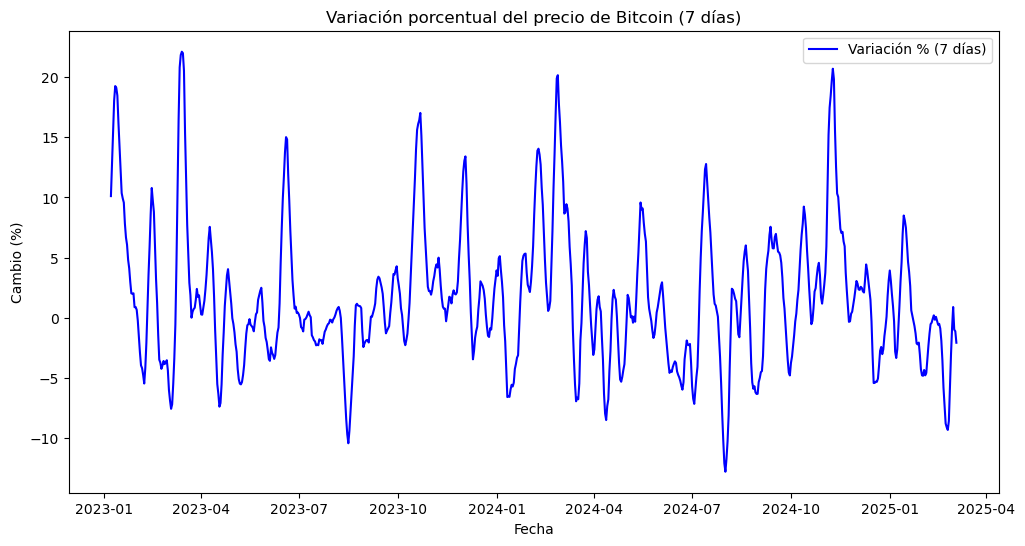

In [70]:
horizonte = 7 

# Asegurarse de que 'timestamp' es índice y en formato datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])
df.set_index("timestamp", inplace=True)

# Visualizar la serie temporal de la variación porcentual
plt.figure(figsize=(12,6))
plt.plot(df.index, df[f'pct_cambio_{horizonte}d'], label=f'Variación % ({horizonte} días)', color='blue')
plt.title(f'Variación porcentual del precio de Bitcoin ({horizonte} días)')
plt.xlabel('Fecha')
plt.ylabel('Cambio (%)')
plt.legend()
plt.show()

*Conclusión*: La gráfica anterior representa la evolución temporal de la variable objetivo pct_cambio_7d, que mide el porcentaje de cambio del precio del Bitcoin en intervalos de 7 días consecutivos. Esta visualización permite apreciar la naturaleza altamente volátil de la variable respuesta, con oscilaciones frecuentes entre valores positivos y negativos. Se observan picos bruscos de crecimiento y caídas, reflejo de la inestabilidad inherente al mercado de criptomonedas. La serie no presenta una tendencia clara ni patrones visualmente recurrentes, lo que refuerza la complejidad del problema de predicción. Esta alta fluctuación sugiere que el modelo deberá ser capaz de adaptarse a movimientos abruptos y dinámicas cambiantes en cortos periodos de tiempo.

# Exploración de la estructura temporal de la variable respuesta a 7 días

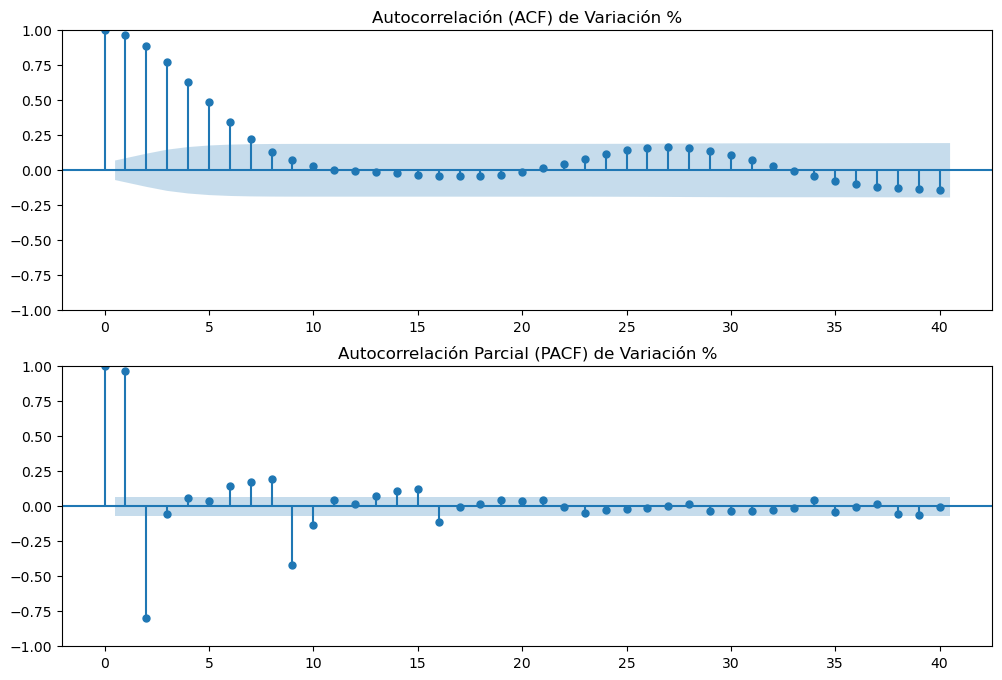

In [74]:
fig, ax = plt.subplots(2,1, figsize=(12,8))
plot_acf(df[f'pct_cambio_{horizonte}d'].dropna(), ax=ax[0], lags=40)  # ACF hasta 40 retrasos
plot_pacf(df[f'pct_cambio_{horizonte}d'].dropna(), ax=ax[1], lags=40) # PACF hasta 40 retrasos
ax[0].set_title("Autocorrelación (ACF) de Variación %")
ax[1].set_title("Autocorrelación Parcial (PACF) de Variación %")
plt.show()

*Conclusiones*: En esta sección hemos analizado la posible existencia de dependencia temporal en la variable objetivo pct_cambio_7d, es decir, si los valores pasados de la serie influyen en su comportamiento futuro. La intuición detrás de este análisis es que lo que ocurrió en días o semanas anteriores podría tener un efecto sobre lo que ocurrirá en los próximos días. Los resultados del análisis de autocorrelación muestran que existe una relación temporal significativa en los primeros lags, lo que indica que la variable no es completamente aleatoria y que podría ser parcialmente predecible a corto plazo. No obstante, el comportamiento altamente volátil y abrupto de la serie implica que, aunque exista cierta estructura, predecir con precisión los cambios semanales sigue siendo una tarea compleja. Por ello, los modelos que se utilicen deberán ser capaces de capturar patrones sutiles y adaptarse a cambios frecuentes en la dinámica del mercado.

# Análisis estructural de la variable respuesta a 7 días: tendencia y estacionalidad

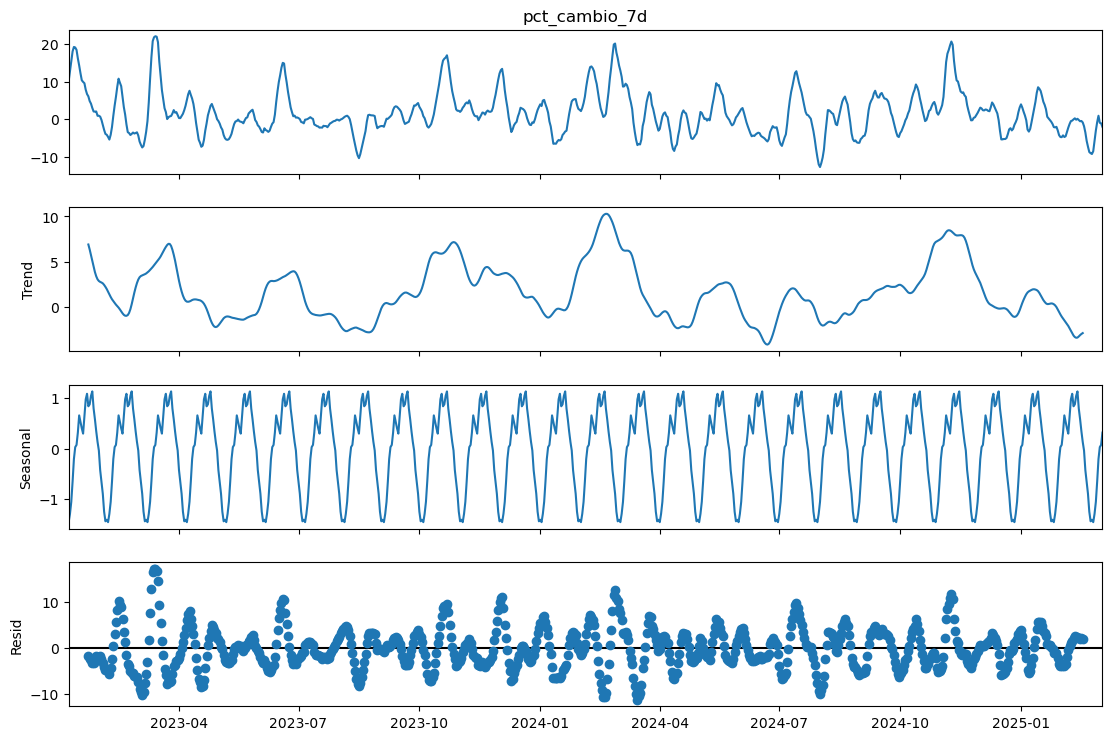

In [78]:
decomposition = sm.tsa.seasonal_decompose(df[f'pct_cambio_{horizonte}d'].dropna(), model='additive', period=30)

fig = decomposition.plot()
fig.set_size_inches(12,8)
plt.show()

*Conclusión*: La descomposición estacional de la variable pct_cambio_7d permite estudiar su estructura interna separando los componentes de tendencia, estacionalidad y ruido. En la primera gráfica se observa de nuevo la alta volatilidad de la serie original, con picos pronunciados tanto positivos como negativos. La componente de tendencia revela movimientos más suaves y sostenidos a lo largo del tiempo, lo que sugiere que, aunque a corto plazo el comportamiento es errático, pueden existir fases de crecimiento o caída más prolongadas. Por otro lado, la componente estacional muestra un patrón cíclico claro, lo que indica que existen fluctuaciones recurrentes en la serie con cierta regularidad (posiblemente semanal o mensual). Finalmente, la componente residual contiene variaciones abruptas y aparentemente aleatorias, que representan la parte impredecible del mercado. En conjunto, esta descomposición confirma que la variable respuesta no es completamente aleatoria: contiene elementos estructurados que los modelos pueden intentar capturar, aunque siempre existirá una parte residual de alta incertidumbre debido a la naturaleza impredecible del mercado de criptomonedas.

# Correlacion con variable respuesta

In [4]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volumen_binance', 'trades_binance',
                 'close_sp500', 'high_sp500', 'low_sp500', 'open_sp500', 'volume_sp500',
                 'close_nasdaq', 'high_nasdaq', 'low_nasdaq', 'open_nasdaq', 'volume_nasdaq',
                 'close_dxy', 'high_dxy', 'low_dxy', 'open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

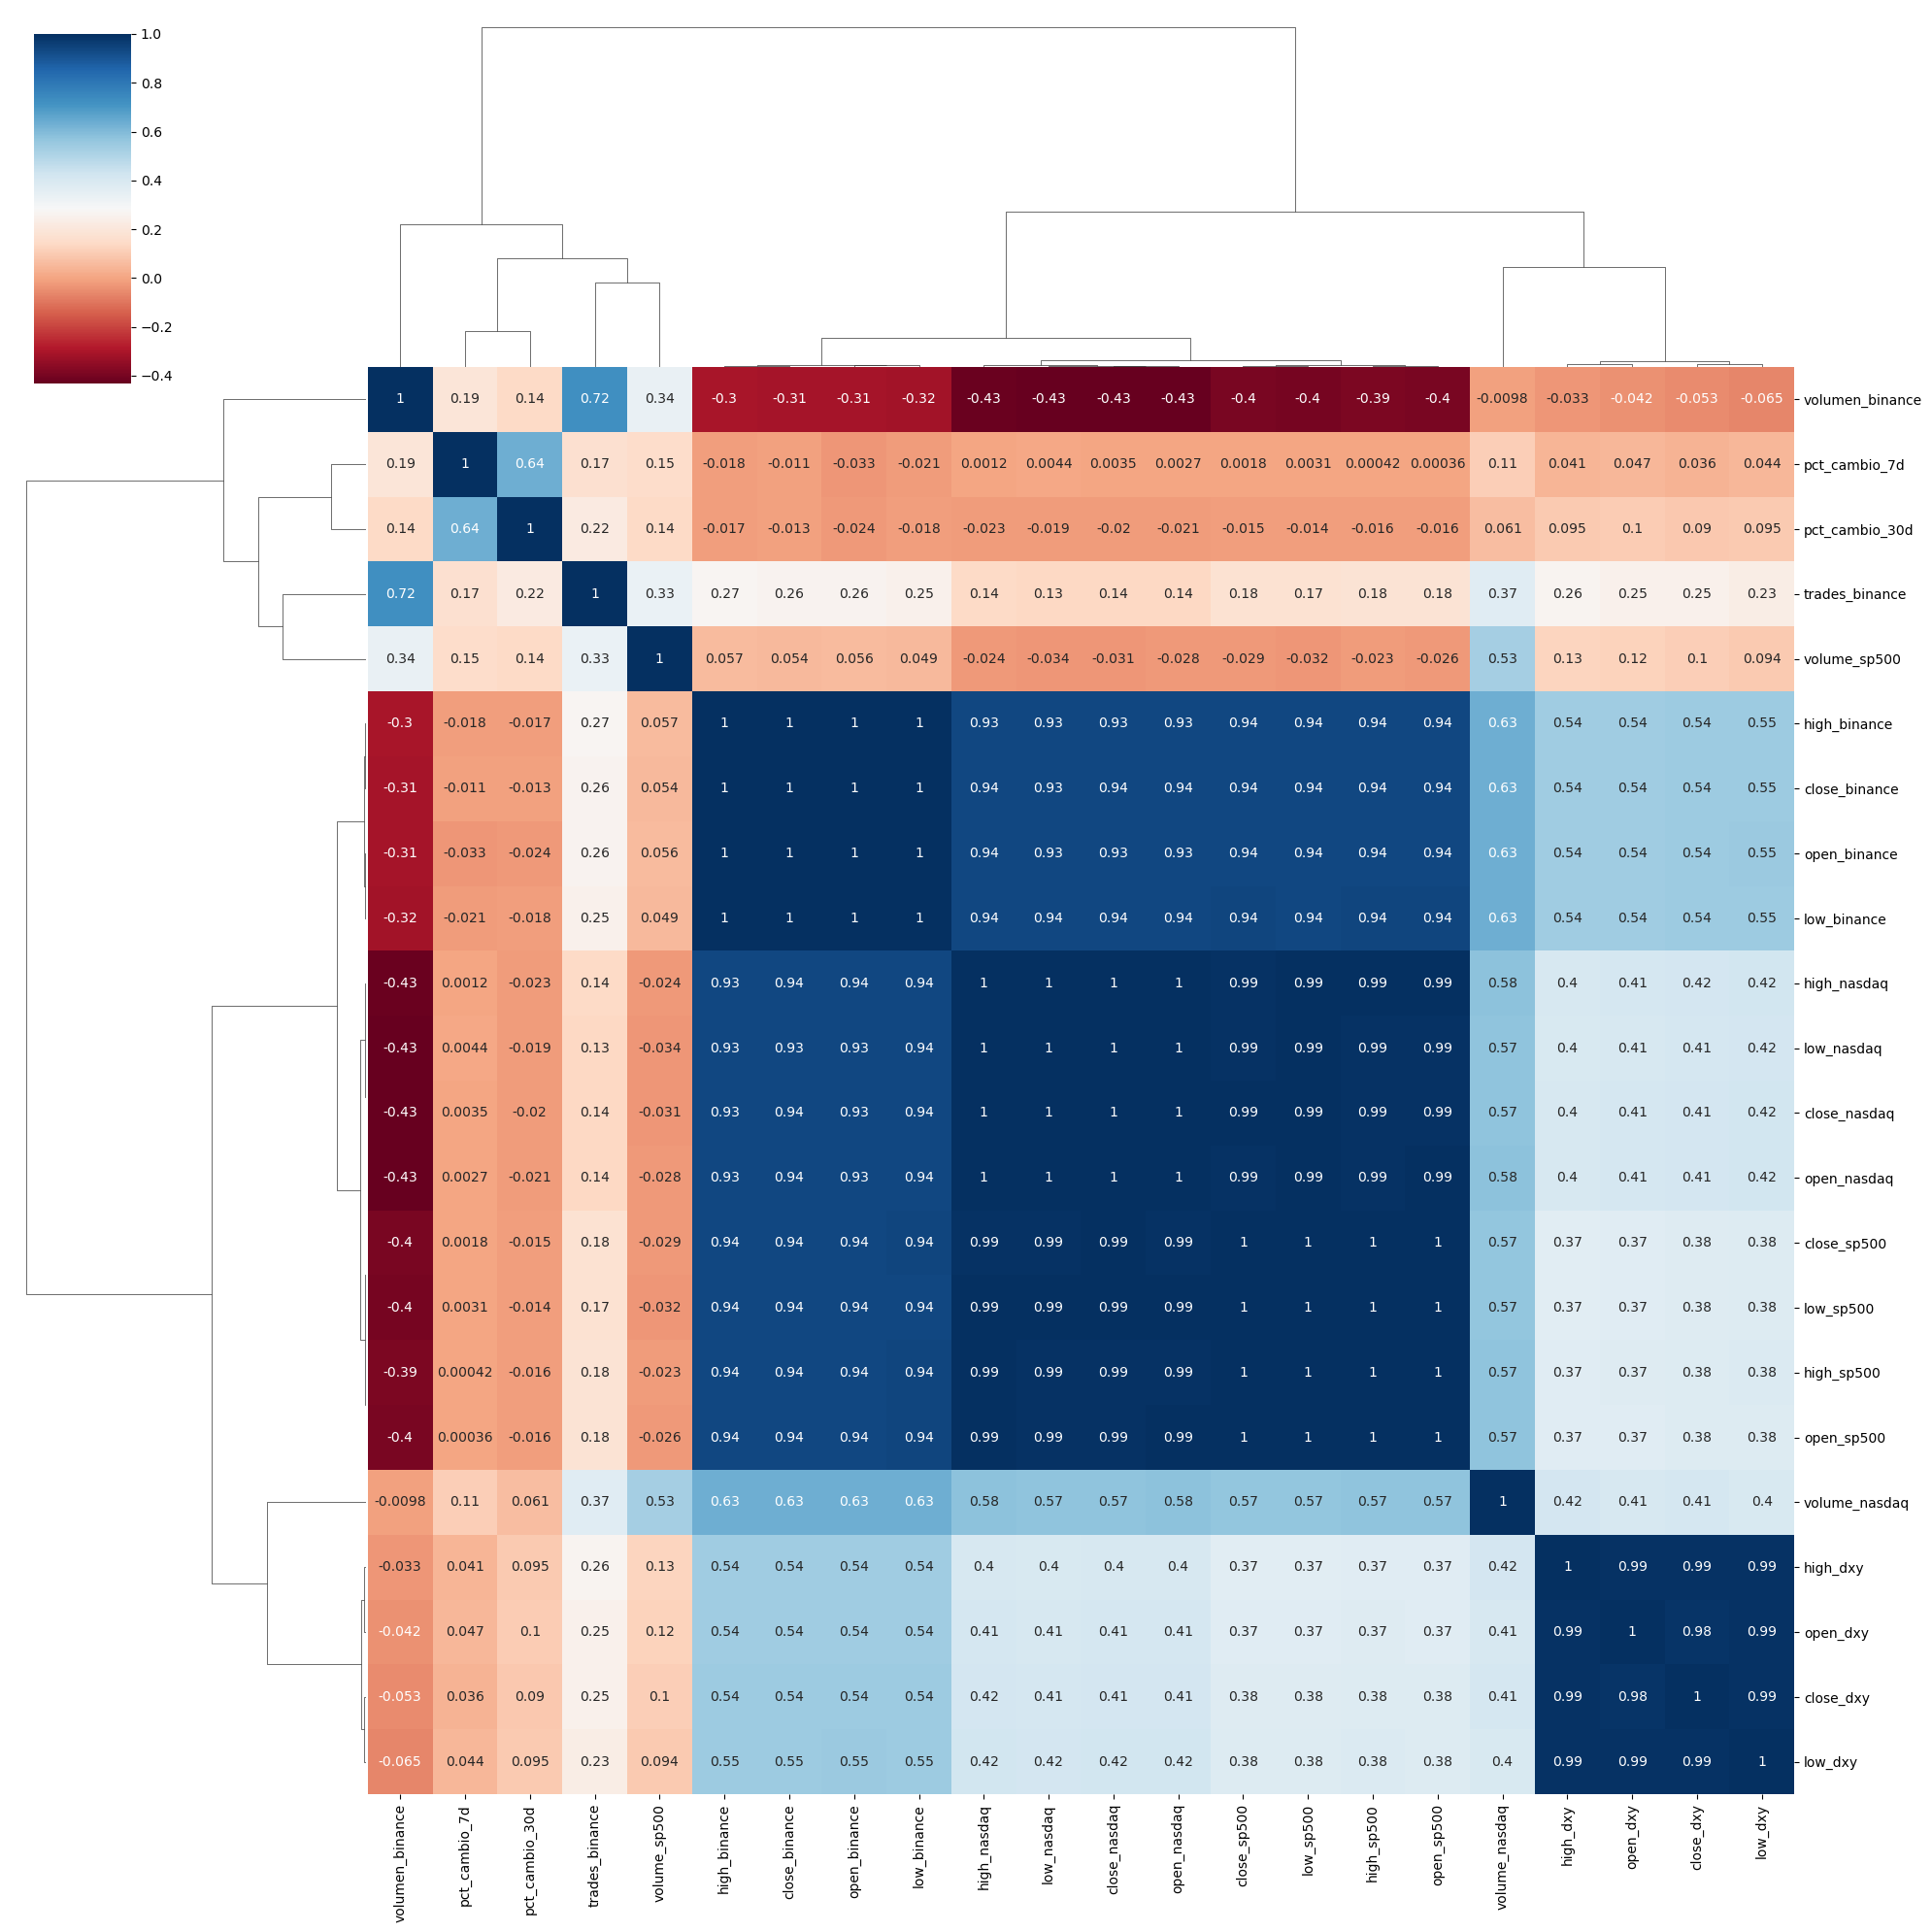

In [5]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()